In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb


In [18]:
wine = pd.read_csv('wine_data.csv', usecols= [0, 1, 2], names=["Class label", "Alcohol", "Malic acid"], header=0)
wine1 = pd.read_csv('wine_data.csv', usecols= [0, 1, 2], names=["Class label", "Alcohol", "Malic acid"], header=0)

In [5]:
wine['Malic acid'].min()

0.74

# Min-Max Normalization

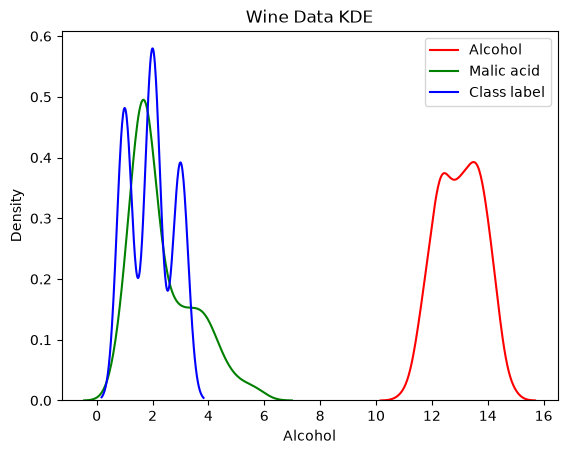

In [11]:
sb.kdeplot(wine['Alcohol'], color= "red", label= "Alcohol")
sb.kdeplot(wine['Malic acid'], color= "Green", label="Malic acid" )
sb.kdeplot(wine["Class label"], color= "blue", label= "Class label")

plt.title("Wine Data KDE")
plt.legend()

<Axes: xlabel='Alcohol', ylabel='Malic acid'>

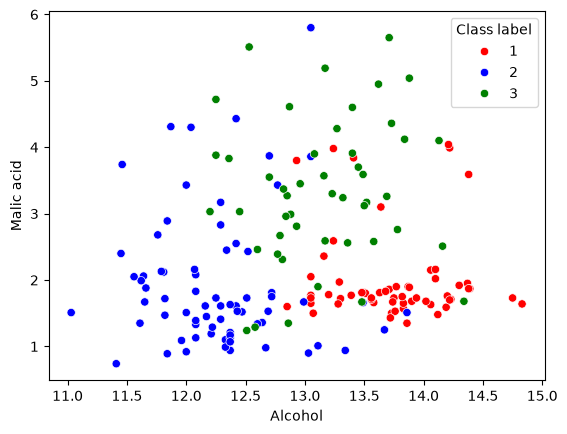

In [17]:
dictH = {1: "Red", 2: "Blue", 3: "Green"}
sb.scatterplot(x= "Alcohol", y= "Malic acid", hue= "Class label", data= wine, palette=dictH)

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(wine1.drop("Class label", axis= 1),
                                                   wine1["Class label"],
                                                   test_size=0.3,
                                                   random_state=0)



In [22]:
X_train.shape, X_test.shape

((124, 2), (54, 2))

In [23]:
Y_train.shape, Y_test.shape

((124,), (54,))

In [25]:
from sklearn.preprocessing import MinMaxScaler
minMax = MinMaxScaler()

minMax.fit(X_train)

X_train_scaled = minMax.transform(X_train)
X_test_scaled = minMax.transform(X_test)


In [26]:
X_test_scaled_1 = pd.DataFrame(X_test_scaled, columns= X_test.columns)
X_train_scaled_1 = pd.DataFrame(X_train_scaled, columns= X_train.columns)

In [30]:
np.round(X_train_scaled_1.describe(), 1)

,Alcohol,Malic acid
count,124.0,124.0
mean,0.5,0.3
std,0.2,0.2
min,0.0,0.0
25%,0.4,0.2
50%,0.5,0.2
75%,0.7,0.5
max,1.0,1.0


Text(0.5, 1.0, 'After Scaling')

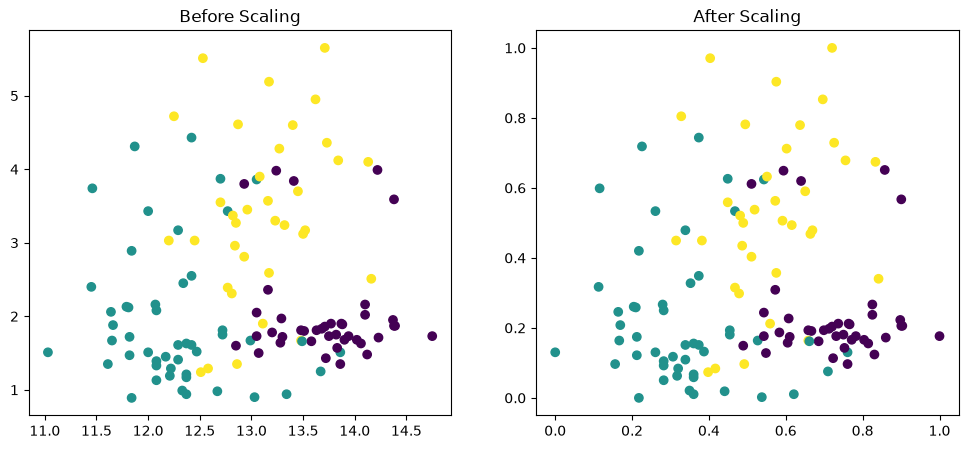

In [40]:
fig, (ax1, ax2) = plt.subplots(ncols= 2, figsize= (12, 5))

ax1.scatter(x= "Alcohol", y= "Malic acid", data= X_train, c= Y_train)
ax1.set_title("Before Scaling")

ax2.scatter(x= "Alcohol", y= "Malic acid", data= X_train_scaled_1, c= Y_train)
ax2.set_title("After Scaling")

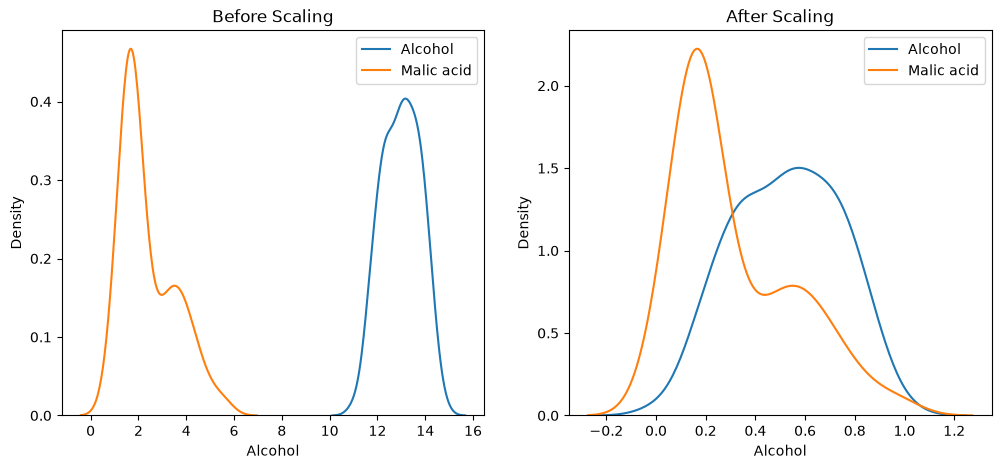

In [51]:
fig, (ax1, ax2) = plt.subplots(ncols= 2, figsize= (12, 5))

ax1.set_title("Before Scaling")
sb.kdeplot(X_train["Alcohol"], ax= ax1, label= "Alcohol")
sb.kdeplot(X_train["Malic acid"], ax= ax1, label= "Malic acid")
ax1.legend()

sb.kdeplot(X_train_scaled_1["Alcohol"], ax= ax2, label= "Alcohol")
sb.kdeplot(X_train_scaled_1["Malic acid"], ax= ax2, label= "Malic acid")
ax2.set_title("After Scaling")

ax2.legend()
plt.show()

In [55]:
# In above the scale became same after Feature Scaling

<Axes: xlabel='Alcohol', ylabel='Malic acid'>

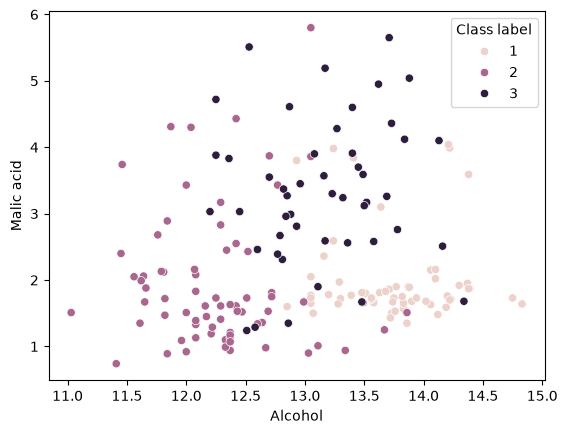

In [54]:
sb.scatterplot(x= "Alcohol", y= "Malic acid", data= wine, hue= "Class label")